### 4. Target Creation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv("../data/interim/deliveries_cleaned.csv")

In [3]:
df.shape

(43648, 22)

In [4]:
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,...,Vehicle,Area,Delivery_Time,Category,Order_DateTime,Pickup_DateTime,Pickup_Next_Day,Distance,Extreme_Distance_Flag,Night_Order_Flag
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,...,motorcycle,Urban,120,Clothing,2022-03-19 11:30:00,2022-03-19 11:45:00,0,3.025149,0,0
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,...,scooter,Metropolitian,165,Electronics,2022-03-25 19:45:00,2022-03-25 19:50:00,0,20.183530,0,0
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,...,motorcycle,Urban,130,Sports,2022-03-19 08:30:00,2022-03-19 08:45:00,0,1.552758,0,0
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,...,motorcycle,Metropolitian,105,Cosmetics,2022-04-05 18:00:00,2022-04-05 18:10:00,0,7.790401,0,0
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,...,scooter,Metropolitian,150,Toys,2022-03-26 13:30:00,2022-03-26 13:45:00,0,6.210138,0,0


In [5]:
df["Delivery_Time"].describe()


count    43648.000000
mean       124.914475
std         51.933163
min         10.000000
25%         90.000000
50%        125.000000
75%        160.000000
max        270.000000
Name: Delivery_Time, dtype: float64

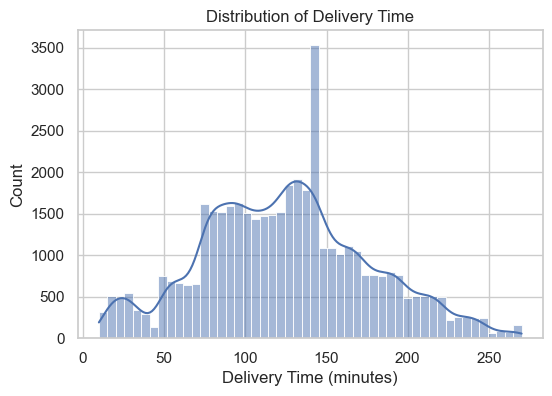

In [6]:
plt.figure(figsize=(6,4))
sns.histplot(df["Delivery_Time"], bins=50, kde=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.show()

On-Time   : ≤ 50th percentile (≤ 13.8 min/km)
At Risk   : 50–80th percentile (13.8 – ~22.7)
Delayed   : > 80th percentile (> ~22.7)
This gives you:

~50% On-Time

~30% At Risk

~20% Delayed

Which is:

Balanced

Interpretable

Strong for multiclass ML

6️⃣ Why NOT 75 & 90 for your case?
75th already includes many borderline-slow cases

90th may isolate only extreme inefficiencies

You’d risk making Delayed too small

Your earlier Delivery_Time analysis already used 80th

In [9]:
df["Minutes_per_km"] = df["Delivery_Time"] / df["Distance"]

In [10]:
df["Minutes_per_km"].describe()

count    43648.000000
mean        19.951492
std         19.316962
min          0.002665
25%          8.776358
50%         13.803652
75%         22.655721
max        176.885700
Name: Minutes_per_km, dtype: float64

Exclude extreme-distance rows from dynamic target computation

They don’t belong to the same operational regime.

In [24]:
mask = df["Extreme_Distance_Flag"] == 0

p50 = df.loc[mask, "Minutes_per_km"].quantile(0.50)
p80 = df.loc[mask, "Minutes_per_km"].quantile(0.80)

In [25]:
def assign_category_dynamic(x):
    if x <= p50:
        return "On-Time"
    elif x <= p80:
        return "At Risk"
    else:
        return "Delayed"

df["Category"] = df["Minutes_per_km"].apply(assign_category_dynamic)

In [26]:
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,...,Area,Delivery_Time,Category,Order_DateTime,Pickup_DateTime,Pickup_Next_Day,Distance,Extreme_Distance_Flag,Night_Order_Flag,Minutes_per_km
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,...,Urban,120,Delayed,2022-03-19 11:30:00,2022-03-19 11:45:00,0,3.025149,0,0,39.667464
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,...,Metropolitian,165,On-Time,2022-03-25 19:45:00,2022-03-25 19:50:00,0,20.183530,0,0,8.174982
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,...,Urban,130,Delayed,2022-03-19 08:30:00,2022-03-19 08:45:00,0,1.552758,0,0,83.722007
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,...,Metropolitian,105,On-Time,2022-04-05 18:00:00,2022-04-05 18:10:00,0,7.790401,0,0,13.478125
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,...,Metropolitian,150,At Risk,2022-03-26 13:30:00,2022-03-26 13:45:00,0,6.210138,0,0,24.154053


In [27]:
df["Category"].value_counts()

Category
On-Time    21902
At Risk    13047
Delayed     8699
Name: count, dtype: int64

In [28]:
df["Category"].value_counts(normalize=True)

Category
On-Time    0.501787
At Risk    0.298914
Delayed    0.199299
Name: proportion, dtype: float64

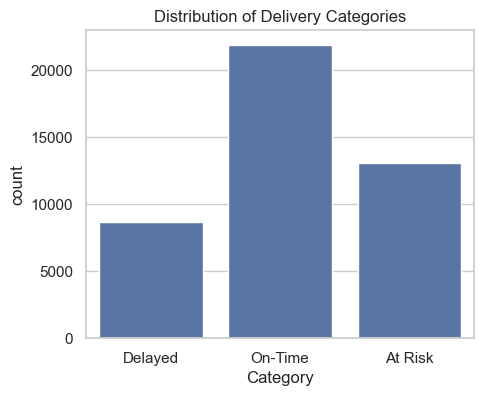

In [29]:
plt.figure(figsize=(5,4))
sns.countplot(x="Category", data=df)
plt.title("Distribution of Delivery Categories")
plt.show()

In [32]:
df[
    df["Minutes_per_km"].between(p50 * 0.95, p50 * 1.05)
][["Minutes_per_km", "Category"]].head(10)

,Minutes_per_km,Category
3,13.478125,On-Time
26,13.886813,At Risk
30,14.470606,At Risk
31,13.600465,On-Time
46,13.419117,On-Time
49,13.251120,On-Time
52,14.441210,At Risk
63,13.869510,On-Time
70,13.978214,At Risk
75,13.243036,On-Time


In [33]:
df[
    df["Minutes_per_km"].between(p80 * 0.95, p80 * 1.05)
][["Minutes_per_km", "Category"]].head(10)

,Minutes_per_km,Category
23,27.791530,Delayed
29,27.812412,Delayed
72,27.026448,Delayed
117,27.966578,Delayed
182,27.404675,Delayed
185,27.653947,Delayed
224,26.496518,At Risk
385,27.547776,Delayed
390,25.770365,At Risk
423,27.780411,Delayed


In [34]:
pd.crosstab(df["Night_Order_Flag"], df["Category"], normalize="index")

Category,At Risk,Delayed,On-Time
Night_Order_Flag,,,
0,0.328601,0.247168,0.424231
1,0.191987,0.026885,0.781128


In [36]:
df.to_csv("../data/processed/deliveries_with_target.csv", index=False)